In [1]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Datasets/adult/adult.csv')
df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [3]:
# Drop rows with missing values
df.replace("?", np.nan, inplace=True)
df.dropna(inplace=True)
df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
5,34,Private,198693,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K


In [4]:
label_encoders = {}
for column in df.columns:
    if df[column].dtype == 'object':
        le = LabelEncoder()
        df[column] = le.fit_transform(df[column])
        label_encoders[column] = le

CART Accuracy: 0.8432283029297954
CART Decision Tree Evaluation
Accuracy: 0.8432283029297954
              precision    recall  f1-score   support

           0       0.86      0.95      0.90      6842
           1       0.77      0.51      0.61      2203

    accuracy                           0.84      9045
   macro avg       0.81      0.73      0.76      9045
weighted avg       0.84      0.84      0.83      9045



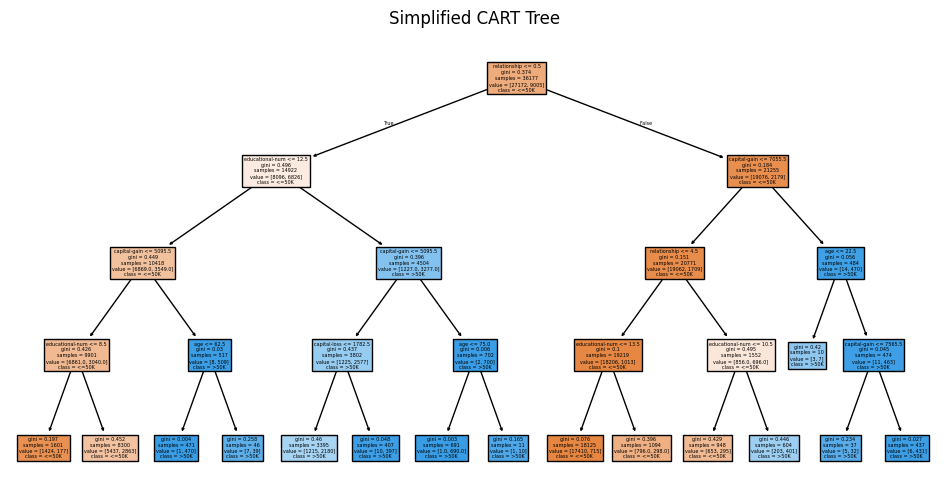

In [19]:
X = df.drop("income", axis=1)
y = df["income"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# CART model
cart_model = DecisionTreeClassifier(
    criterion='gini',      # or 'gini'        
    max_depth=4,            # limit depth
    min_samples_split=2,   # don’t split unless node has 20+ samples
    min_samples_leaf=10     # leaf must have 10+ samples
)
cart_model.fit(X_train, y_train)

# Accuracy
y_pred = cart_model.predict(X_test)
print("CART Accuracy:", accuracy_score(y_test, y_pred))

print("CART Decision Tree Evaluation")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Plot the tree
plt.figure(figsize=(12, 6))
plot_tree(cart_model, feature_names=X.columns, class_names=label_encoders["income"].classes_, filled=True)
plt.title("Simplified CART Tree")
plt.show()